REPRESENTACION LA DISTRIBUCIÓN DE LAS ETIQUETAS DE LAS BBDD

In [5]:
import pandas as pd
import os 
import numpy as np 
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

def count_df (data_path, embedding_path, NAME,slide_col='image_id', printing=False):
    features_list = []
    labels_list = []
    patient_list = []
    gleason_score = []
    gleason_primary_list = []
    gleason_secondary_list = []
    df = pd.read_excel(data_path)
    embeddings = [f for f in os.listdir(embedding_path) if f.endswith('.h5')]

    existing_h5 = 0
    # Agrega tqdm aquí
    for f in tqdm(embeddings, desc="Procesando embeddings"):
        slide_id = f.split('.h5')[0]
        if NAME == 'SICAP':
            slide_id = slide_id.split('_')[0]
        row = df[df[slide_col] == slide_id]

        if not row.empty:
            ruta_npy = os.path.join(embedding_path, f)
            if  os.path.exists(ruta_npy):
                existing_h5+=1

            gleason = row[['gleason_score']].values
            patient_select = row['image_id'].values
            labels_selected = row[['gleason_primary', 'gleason_secondary']].values
            labels_selected = np.array(labels_selected, dtype=int)[0]

            gleason_score.append(gleason.item())
            features_list.append(ruta_npy)
            labels_list.append(labels_selected)
            patient_list.append(patient_select)
            gleason_primary_list.append(row['gleason_primary'].values[0])
            gleason_secondary_list.append(row['gleason_secondary'].values[0])
    print(existing_h5)
   
    
    # Crear DataFrame con los valores
    df_gleason = pd.DataFrame({
        'Gleason_primary': gleason_primary_list,
        'Gleason_secondary': gleason_secondary_list
    })

    # Crear la tabla cruzada (conteo de combinaciones)
    tabla = pd.crosstab(df_gleason['Gleason_primary'], df_gleason['Gleason_secondary'])
  
    if printing == True:
        print(f"Nº imagenes en Base de datos {NAME} : {len(features_list)}")
        print(f"Nº de pacientes en {NAME}: {len(patient_list)}")

        plt.figure(figsize=(6,5))
        sns.heatmap(tabla, annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Gleason secundario')
        plt.ylabel('Gleason primario')
        plt.title('Distribución Gleason Primario vs Secundario')
        plt.show()

    df_train = pd.DataFrame({
        'features': features_list,
        'labels': labels_list,
        'gleason_score': gleason_score,
        'gleason_primary': gleason_primary_list,
        'gleason_secondary': gleason_secondary_list
    })

    return df_train



~ PANDA

Procesando embeddings: 100%|██████████| 10569/10569 [00:14<00:00, 719.70it/s]


Nº imagenes en Base de datos PANDA : 9614
Nº de pacientes en PANDA: 9614


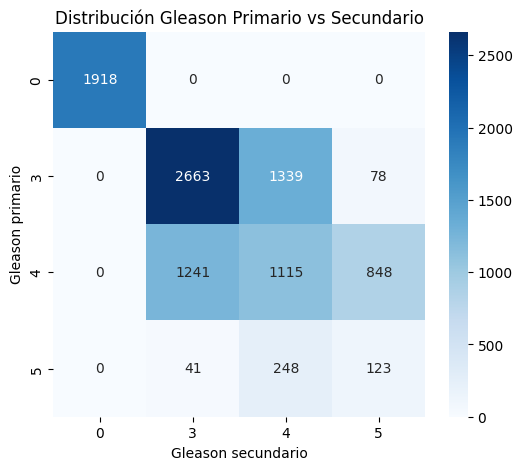

In [18]:
data_path_panda = '/workspace/data/datos_PANDAS.xlsx'
embedding_path_panda = '/workspace/data/pandas/embeddings/KEEP'
df_pandas = count_df (data_path_panda, embedding_path_panda, 'PANDA',slide_col='image_id', printing=True)

~ SICAP

Procesando embeddings: 100%|██████████| 230/230 [00:00<00:00, 915.46it/s]


228
Nº imagenes en Base de datos SICAP : 228
Nº de pacientes en SICAP: 228


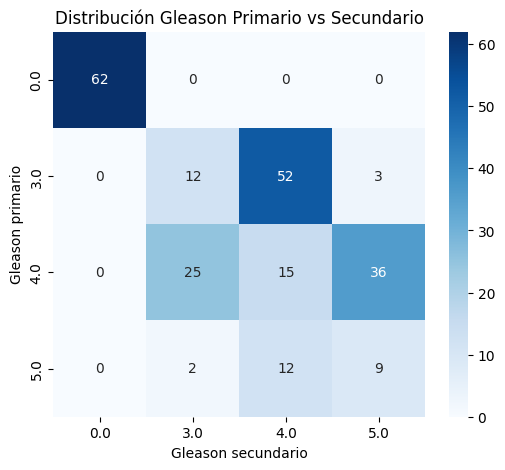

In [6]:
data_path = '/workspace/data/wsi_labels_changed_SICAP.xlsx'
embedding_path = '/workspace/data/features_SICAP/patches'
df_sicap = count_df (data_path, embedding_path, 'SICAP',slide_col='image_id', printing=True)

ANÁLISIS DEL NUMERO DE PARCHES POR WSI 

In [20]:
import os
import h5py
import matplotlib.pyplot as plt
from tqdm import tqdm 

def cargar_dimensiones_h5(carpeta, summary=False):
    """
    Recorre una carpeta, carga cada archivo .h5 y extrae
    la primera dimensión del primer dataset encontrado.
    
    Retorna: diccionario {nombre_archivo: primera_dimensión}
    """
    resultados = {}
    if summary == True:
        frame_0 = os.listdir(carpeta)[0]
        ruta = os.path.join(carpeta, frame_0)
        with h5py.File(ruta, "r") as f:
            # Obtener el primer dataset del archivo
            data = f['imgs'][:]

        # Tamaño de la primera dimensión
        dim0 = data.shape[0]

        resultados[frame_0] = dim0
        len_wsi = len(os.listdir(carpeta))
        print(f" Numero de WSis : {len_wsi}")
        print(f"Nuemro de parches de la primera WSI: {resultados}")

    else: 
        for fname in tqdm(os.listdir(carpeta),desc='Reading WSIs'):
            

            if not fname.endswith((".h5")):
                continue
            
            ruta = os.path.join(carpeta, fname)

            try:
                with h5py.File(ruta, "r") as f:
                    # Obtener el primer dataset del archivo
                    data = f['imgs'][:]

                    # Tamaño de la primera dimensión
                    dim0 = data.shape[0]

                    resultados[fname] = dim0

            except Exception as e:
                print(f"Error al leer {fname}: {e}")

    return resultados

In [2]:
def graficar_dimensiones(resultados):
    """
    Grafica los valores de la primera dimensión obtenidos.
    """
    nombres = list(resultados.keys())
    valores = list(resultados.values())

    plt.figure(figsize=(10, 5))
    plt.plot(valores, marker="o")
    plt.xticks(range(len(nombres)), nombres, rotation=90)
    plt.xlabel("WSIs (Archivos H5)")
    plt.ylabel("Número de parches")
    plt.title("Número de parches por WSI")
    plt.tight_layout()
    plt.show()

 Numero de WSis : 9216
Nuemro de parches de la primera WSI: {'0005f7aaab2800f6170c399693a96917.h5': 36}
{'0005f7aaab2800f6170c399693a96917.h5': 36}
 TIempo de carga: 16721.173828125


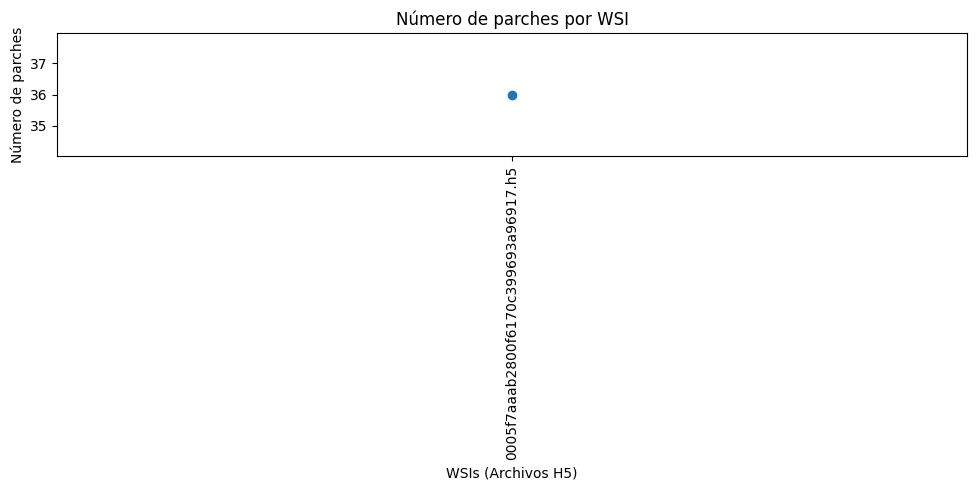

In [22]:
import time
# PANDAS
carpeta = '/workspace/data/pandas/patches'

start_time = time.time()
resultados = cargar_dimensiones_h5(carpeta, summary = True)
ending_time = time.time()

print(resultados)
print(f" TIempo de carga: {(ending_time - start_time)*9216}")
graficar_dimensiones(resultados)

Reading WSIs:   0%|          | 0/230 [00:00<?, ?it/s]

Reading WSIs: 100%|██████████| 230/230 [01:58<00:00,  1.94it/s]


{'16B0003388_13.h5': 23, '16B0003394_1.h5': 23, '16B0006668_3.h5': 36, '16B0006694_1.h5': 44, '16B0006695_3.h5': 48, '16B0008066_0.h5': 12, '16B0008067_0.h5': 40, '16B0022610_9.h5': 18, '16B0022612_1.h5': 48, '16B0022613_2.h5': 43, '16B0022615_4.h5': 37, '16B0022781_7.h5': 21, '16B0022786_0.h5': 30, '16B0023613_3.h5': 46, '16B0023614_2.h5': 32, '16B0024173_2.h5': 22, '16B0024174_0.h5': 44, '16B0024177_0.h5': 23, '16B0024181_2.h5': 35, '16B0026792_3.h5': 36, '16B0026794_11.h5': 50, '16B0026795_10.h5': 46, '16B0026796_3.h5': 38, '16B0027038_0.h5': 37, '16B0027039_3.h5': 32, '16B0027040_1.h5': 39, '16B0028138_0.h5': 27, '16B0028148_3.h5': 19, '16B0028168_0.h5': 25, '16B0028813_5.h5': 40, '16B0028814_2.h5': 35, '16B0028815_3.h5': 41, '16B0028816_6.h5': 28, '16B0028817_8.h5': 30, '16B0028822_1.h5': 29, '16B0028914_1.h5': 48, '17B00116581_15.h5': 25, '17B0011996_5.h5': 45, '17B0015777_4.h5': 26, '17B0016566_2.h5': 40, '17B0016579_6.h5': 36, '17B0016583_3.h5': 23, '17B0016589_0.h5': 46, '17B0

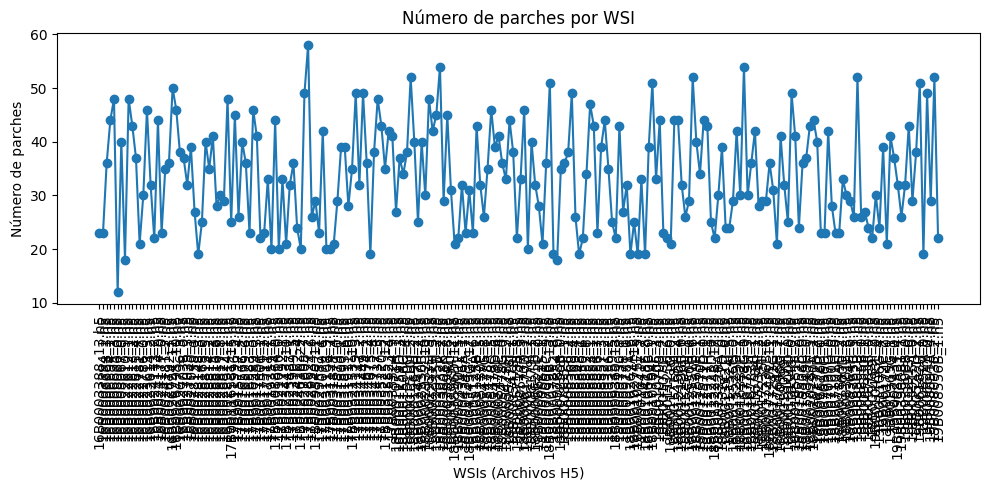

In [4]:
# SICAP
carpeta = '/workspace/data/features_SICAP/patches'

resultados = cargar_dimensiones_h5(carpeta)
print(resultados)

graficar_dimensiones(resultados)

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
import pandas as pd

def generar_tabla_resumen(df_pandas):
    # --- 1️⃣ Dividir en train, val y test ---
    train_val_idx, test_idx = train_test_split(
        df_pandas.index, test_size=0.15, stratify=df_pandas["gleason_score"]
    )

    train_idx, val_idx = train_test_split(
        train_val_idx, test_size=0.10, stratify=df_pandas.loc[train_val_idx]["gleason_score"]
    )

    # Crear subconjuntos
    df_train = df_pandas.loc[train_idx]
    df_val = df_pandas.loc[val_idx]
    df_test = df_pandas.loc[test_idx]

    # --- 2️⃣ Función auxiliar para contar clases ---
    def contar_por_columna(df, columna):
        return df[columna].value_counts().sort_index()

    # --- 3️⃣ Construir tablas ---
    tipos = ['gleason_primary', 'gleason_secondary', 'gleason_score']
    tablas = {}

    for tipo in tipos:
        # Combinar en un solo DataFrame
        tabla = pd.concat([
            contar_por_columna(df_train, tipo).rename('Train'),
            contar_por_columna(df_val, tipo).rename('Validation'),
            contar_por_columna(df_test, tipo).rename('Test')
        ], axis=1).fillna(0).astype(int)

        tablas[tipo] = tabla

    # --- 4️⃣ Mostrar resultados ---
    for nombre, tabla in tablas.items():
        print(f"\n📊 Tabla resumen por {nombre.replace('_', ' ').title()}")
        print(tabla)
    
    return tablas  # Devuelve un diccionario con las 3 tablas


In [ ]:
tabla = generar_tabla_resumen(df_pandas)


📊 Tabla resumen por Gleason Primary
   Train  Validation  Test
0   1467         163   288
3   3129         348   603
4   2446         275   483
5    311          32    69

📊 Tabla resumen por Gleason Secondary
   Train  Validation  Test
0   1467         163   288
3   3010         335   600
4   2065         230   407
5    811          90   148

📊 Tabla resumen por Gleason Score
    Train  Validation  Test
0    1467         163   288
6    2036         227   400
7    1973         220   387
8     944         105   185
9     838          93   165
10     95          10    18


In [ ]:
# MEMORIA DE ESTRUCTURA 
import sys 
ruta_actual = os.getcwd()   
sys.path.append(os.path.abspath(os.path.join(ruta_actual, "..")))
from models.model_1graph import get_keep_ia3_model
import torch
from pympler import asizeof

model = get_keep_ia3_model()

mem_bytes = asizeof.asizeof(model)
print(f"Memoria total del modelo en RAM: {mem_bytes / (1024**2):.2f} MB")

torch.cuda.reset_peak_memory_stats()
model = get_keep_ia3_model().cuda()

print(f"Memoria actual en GPU: {torch.cuda.memory_allocated()/1024**2:.2f} MB")
print(f"Pico de memoria GPU: {torch.cuda.max_memory_allocated()/1024**2:.2f} MB")

The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.
`low_cpu_mem_usage` was None, now set to True since model is quantized.


Memoria total del modelo en RAM: 3.21 MB


The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.
`low_cpu_mem_usage` was None, now set to True since model is quantized.


Memoria actual en GPU: 1360.23 MB
Pico de memoria GPU: 1378.77 MB
